In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
%matplotlib inline

In [3]:
# Load the dataset
file_path = r"C:\Users\raoan\OneDrive\Desktop\Flight_Price_Predictor/data/Data_Train.csv"
data = pd.read_csv(file_path)

print("Initial Data Sample:")
print(data.head())
print("\nShape:", data.shape)
print("\nMissing values per column:")
print(data.isnull().sum())

Initial Data Sample:
       Airline Date_of_Journey    Source Destination                  Route  \
0       IndiGo      24/03/2019  Banglore   New Delhi              BLR ? DEL   
1    Air India       1/05/2019   Kolkata    Banglore  CCU ? IXR ? BBI ? BLR   
2  Jet Airways       9/06/2019     Delhi      Cochin  DEL ? LKO ? BOM ? COK   
3       IndiGo      12/05/2019   Kolkata    Banglore        CCU ? NAG ? BLR   
4       IndiGo      01/03/2019  Banglore   New Delhi        BLR ? NAG ? DEL   

  Dep_Time  Arrival_Time Duration Total_Stops Additional_Info  Price  
0    22:20  01:10 22 Mar   2h 50m    non-stop         No info   3897  
1    05:50         13:15   7h 25m     2 stops         No info   7662  
2    09:25  04:25 10 Jun      19h     2 stops         No info  13882  
3    18:05         23:30   5h 25m      1 stop         No info   6218  
4    16:50         21:35   4h 45m      1 stop         No info  13302  

Shape: (10683, 11)

Missing values per column:
Airline            0
Date_of_J

              Price
count  10683.000000
mean    9087.064121
std     4611.359167
min     1759.000000
25%     5277.000000
50%     8372.000000
75%    12373.000000
max    79512.000000


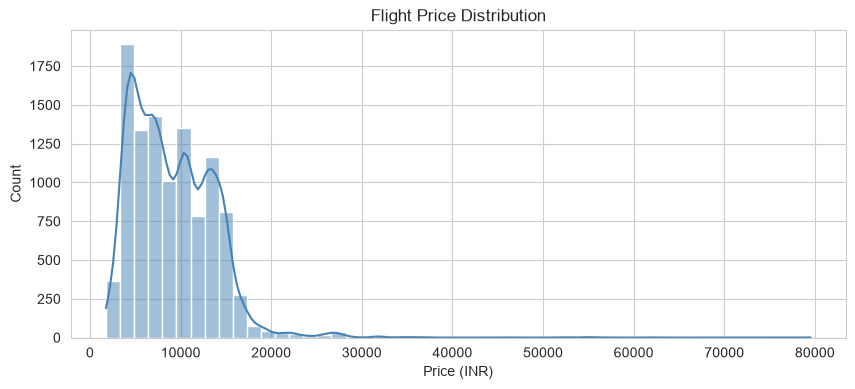

In [4]:
# Statistical summary
print(data.describe())

# Price distribution
plt.figure(figsize=(10, 4))
sns.histplot(data['Price'], bins=50, kde=True, color='steelblue')
plt.title("Flight Price Distribution")
plt.xlabel("Price (INR)")
plt.show()

In [5]:
# Parsing Date of Journey
data['Date_of_Journey'] = pd.to_datetime(data['Date_of_Journey'], format='%d/%m/%Y')
data['Journey_Day'] = data['Date_of_Journey'].dt.day
data['Journey_Month'] = data['Date_of_Journey'].dt.month
data.drop(['Date_of_Journey'], axis=1, inplace=True)

print("After processing Date_of_Journey:")
print(data.head())

After processing Date_of_Journey:
       Airline    Source Destination                  Route Dep_Time  \
0       IndiGo  Banglore   New Delhi              BLR ? DEL    22:20   
1    Air India   Kolkata    Banglore  CCU ? IXR ? BBI ? BLR    05:50   
2  Jet Airways     Delhi      Cochin  DEL ? LKO ? BOM ? COK    09:25   
3       IndiGo   Kolkata    Banglore        CCU ? NAG ? BLR    18:05   
4       IndiGo  Banglore   New Delhi        BLR ? NAG ? DEL    16:50   

   Arrival_Time Duration Total_Stops Additional_Info  Price  Journey_Day  \
0  01:10 22 Mar   2h 50m    non-stop         No info   3897           24   
1         13:15   7h 25m     2 stops         No info   7662            1   
2  04:25 10 Jun      19h     2 stops         No info  13882            9   
3         23:30   5h 25m      1 stop         No info   6218           12   
4         21:35   4h 45m      1 stop         No info  13302            1   

   Journey_Month  
0              3  
1              5  
2              6  


In [6]:
# Extracting Departure time and Hour and Minute
data['Dep_Hour'] = pd.to_datetime(data['Dep_Time'], format='%H:%M', errors='coerce').dt.hour
data['Dep_Min'] = pd.to_datetime(data['Dep_Time'], format='%H:%M', errors='coerce').dt.minute
data.drop(['Dep_Time'], axis=1, inplace=True)

print("After processing Dep_Time:")
print(data.head())

After processing Dep_Time:
       Airline    Source Destination                  Route  Arrival_Time  \
0       IndiGo  Banglore   New Delhi              BLR ? DEL  01:10 22 Mar   
1    Air India   Kolkata    Banglore  CCU ? IXR ? BBI ? BLR         13:15   
2  Jet Airways     Delhi      Cochin  DEL ? LKO ? BOM ? COK  04:25 10 Jun   
3       IndiGo   Kolkata    Banglore        CCU ? NAG ? BLR         23:30   
4       IndiGo  Banglore   New Delhi        BLR ? NAG ? DEL         21:35   

  Duration Total_Stops Additional_Info  Price  Journey_Day  Journey_Month  \
0   2h 50m    non-stop         No info   3897           24              3   
1   7h 25m     2 stops         No info   7662            1              5   
2      19h     2 stops         No info  13882            9              6   
3   5h 25m      1 stop         No info   6218           12              5   
4   4h 45m      1 stop         No info  13302            1              3   

   Dep_Hour  Dep_Min  
0        22       20  
1

In [7]:
# Helper function for Arrival_Time
def parse_arrival_time(t):
    if pd.isnull(t):
        return pd.NaT
    t = str(t).strip()
    time_part = t.split(' ')[0]  # take only the "HH:MM" part
    try:
        return pd.to_datetime(time_part, format='%H:%M')
    except Exception:
        return pd.NaT

# Parse arrival time and extract hour and minute
data['Parsed_Arrival_Time'] = data['Arrival_Time'].apply(parse_arrival_time)
data['Arrival_Hour'] = data['Parsed_Arrival_Time'].apply(lambda x: x.hour if pd.notnull(x) else None)
data['Arrival_Min'] = data['Parsed_Arrival_Time'].apply(lambda x: x.minute if pd.notnull(x) else None)
data.drop(['Arrival_Time', 'Parsed_Arrival_Time'], axis=1, inplace=True)

print("After processing Arrival_Time:")
print(data.head())

After processing Arrival_Time:
       Airline    Source Destination                  Route Duration  \
0       IndiGo  Banglore   New Delhi              BLR ? DEL   2h 50m   
1    Air India   Kolkata    Banglore  CCU ? IXR ? BBI ? BLR   7h 25m   
2  Jet Airways     Delhi      Cochin  DEL ? LKO ? BOM ? COK      19h   
3       IndiGo   Kolkata    Banglore        CCU ? NAG ? BLR   5h 25m   
4       IndiGo  Banglore   New Delhi        BLR ? NAG ? DEL   4h 45m   

  Total_Stops Additional_Info  Price  Journey_Day  Journey_Month  Dep_Hour  \
0    non-stop         No info   3897           24              3        22   
1     2 stops         No info   7662            1              5         5   
2     2 stops         No info  13882            9              6         9   
3      1 stop         No info   6218           12              5        18   
4      1 stop         No info  13302            1              3        16   

   Dep_Min  Arrival_Hour  Arrival_Min  
0       20             1   

In [8]:
# Convert Duration to minutes
def duration_to_minutes(d):
    if pd.isnull(d):
        return np.nan
    d = str(d).strip()
    hours, minutes = 0, 0
    if 'h' in d:
        hours = int(d.split('h')[0].strip())
        rest = d.split('h')[1].strip()
    else:
        rest = d
    if 'm' in rest:
        minutes = int(rest.replace('m', '').strip())
    return hours * 60 + minutes

data['Duration'] = data['Duration'].apply(duration_to_minutes)

print("After processing Duration:")
print(data[['Duration']].head())

After processing Duration:
   Duration
0       170
1       445
2      1140
3       325
4       285


In [9]:
# Drop unneeded columns
data.drop(['Route', 'Additional_Info'], axis=1, inplace=True, errors='ignore')

print("After dropping unneeded columns:")
print("Remaining columns:", data.columns.tolist())
print("New shape:", data.shape)
print(data.head())

After dropping unneeded columns:
Remaining columns: ['Airline', 'Source', 'Destination', 'Duration', 'Total_Stops', 'Price', 'Journey_Day', 'Journey_Month', 'Dep_Hour', 'Dep_Min', 'Arrival_Hour', 'Arrival_Min']
New shape: (10683, 12)
       Airline    Source Destination  Duration Total_Stops  Price  \
0       IndiGo  Banglore   New Delhi       170    non-stop   3897   
1    Air India   Kolkata    Banglore       445     2 stops   7662   
2  Jet Airways     Delhi      Cochin      1140     2 stops  13882   
3       IndiGo   Kolkata    Banglore       325      1 stop   6218   
4       IndiGo  Banglore   New Delhi       285      1 stop  13302   

   Journey_Day  Journey_Month  Dep_Hour  Dep_Min  Arrival_Hour  Arrival_Min  
0           24              3        22       20             1           10  
1            1              5         5       50            13           15  
2            9              6         9       25             4           25  
3           12              5        18

In [10]:
# Check and drop rows with missing values
print("Missing values before:", data.isnull().sum().sum())
data = data.dropna()
print("Missing values after:", data.isnull().sum().sum())
print("Shape after dropping NaN:", data.shape)

Missing values before: 1
Missing values after: 0
Shape after dropping NaN: (10682, 12)


In [11]:
# Handle categorical data (one-hot encoding)
data = pd.get_dummies(data, drop_first=True)

print("After handling categorical data:")
print("New shape:", data.shape)
print(data.head())

After handling categorical data:
New shape: (10682, 32)
   Duration  Price  Journey_Day  Journey_Month  Dep_Hour  Dep_Min  \
0       170   3897           24              3        22       20   
1       445   7662            1              5         5       50   
2      1140  13882            9              6         9       25   
3       325   6218           12              5        18        5   
4       285  13302            1              3        16       50   

   Arrival_Hour  Arrival_Min  Airline_Air India  Airline_GoAir  ...  \
0             1           10              False          False  ...   
1            13           15               True          False  ...   
2             4           25              False          False  ...   
3            23           30              False          False  ...   
4            21           35              False          False  ...   

   Source_Mumbai  Destination_Cochin  Destination_Delhi  \
0          False               False       

In [12]:
# Handle outliers in the target variable using IQR
q1 = data['Price'].quantile(0.25)
q3 = data['Price'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

before = data.shape[0]
data = data[(data['Price'] >= lower_bound) & (data['Price'] <= upper_bound)]
after = data.shape[0]

print(f"Removed {before - after} outlier rows ({(before-after)/before*100:.2f}%)")
print("After handling outliers in Price:")
print("New shape:", data.shape)
print(data.head())

Removed 94 outlier rows (0.88%)
After handling outliers in Price:
New shape: (10588, 32)
   Duration  Price  Journey_Day  Journey_Month  Dep_Hour  Dep_Min  \
0       170   3897           24              3        22       20   
1       445   7662            1              5         5       50   
2      1140  13882            9              6         9       25   
3       325   6218           12              5        18        5   
4       285  13302            1              3        16       50   

   Arrival_Hour  Arrival_Min  Airline_Air India  Airline_GoAir  ...  \
0             1           10              False          False  ...   
1            13           15               True          False  ...   
2             4           25              False          False  ...   
3            23           30              False          False  ...   
4            21           35              False          False  ...   

   Source_Mumbai  Destination_Cochin  Destination_Delhi  \
0         

In [13]:
# Split features and target
X = data.drop(['Price'], axis=1)
y = data['Price']

# Normalize the target variable to [0, 1]
y_min = y.min()
y_max = y.max()
y = (y - y_min) / (y_max - y_min)

print("After normalizing the target variable:")
print(y.head())

# Split the data (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("\nAfter splitting the data:")
print(f"Train set size: {X_train.shape}, Test set size: {X_test.shape}")

# Scale the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("\nAfter scaling the features:")
print(X_train[:5])

After normalizing the target variable:
0    0.100650
1    0.277893
2    0.570709
3    0.209914
4    0.543405
Name: Price, dtype: float64

After splitting the data:
Train set size: (8470, 31), Test set size: (2118, 31)

After scaling the features:
[[ 0.50497727  1.58072153  0.24061254 -1.13768474 -1.3042834   1.11709654
  -1.49283697 -0.44098964 -0.14051606 -0.49334979 -0.74305779  0.
   2.82187224 -0.03766663 -0.28950506  0.         -0.21672925 -0.01536826
  -0.19458419  1.15860574 -0.61255469 -0.26505706  1.15860574 -0.3629707
  -0.26505706 -0.19458419 -0.29827653 -0.40568624 -0.06888366 -0.01086636
  -0.69916959]
 [ 0.12127776  1.22646033  0.24061254 -1.13768474  0.30022103  0.68049176
  -0.58547948 -0.44098964 -0.14051606 -0.49334979  1.34579035  0.
  -0.35437465 -0.03766663 -0.28950506  0.         -0.21672925 -0.01536826
  -0.19458419 -0.86310638  1.63250729 -0.26505706 -0.86310638 -0.3629707
  -0.26505706 -0.19458419 -0.29827653 -0.40568624 -0.06888366 -0.01086636
  -0.69916959]
 

In [14]:
# Train the model with optimized parameters
mlp = MLPRegressor(
    hidden_layer_sizes=(128, 128),
    activation='relu',
    solver='adam',
    max_iter=3000,
    learning_rate_init=0.0005,
    random_state=42,
    alpha=0.001
)

print("MLP Model Configuration:")
print(mlp)

mlp.fit(X_train, y_train)
print("\nTraining complete.")

MLP Model Configuration:
MLPRegressor(alpha=0.001, hidden_layer_sizes=(128, 128),
             learning_rate_init=0.0005, max_iter=3000, random_state=42)

Training complete.


In [15]:
y_pred = mlp.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse}")
print(f"Mean Absolute Error: {mae}")
print(f"R2 Score: {r2}")

Mean Squared Error: 0.016967504655581483
Mean Absolute Error: 0.07204255873513454
R2 Score: 0.5327046413783657


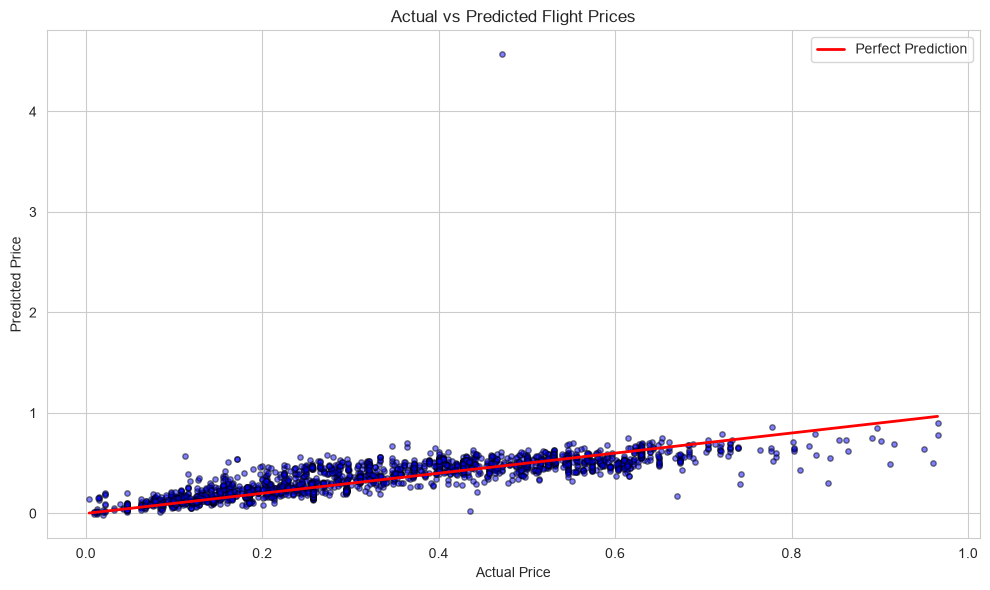

In [16]:
# Scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.5, edgecolor='k', s=15)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red', lw=2, label='Perfect Prediction')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Flight Prices')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('../scatter_plot.png', dpi=150)
plt.show()

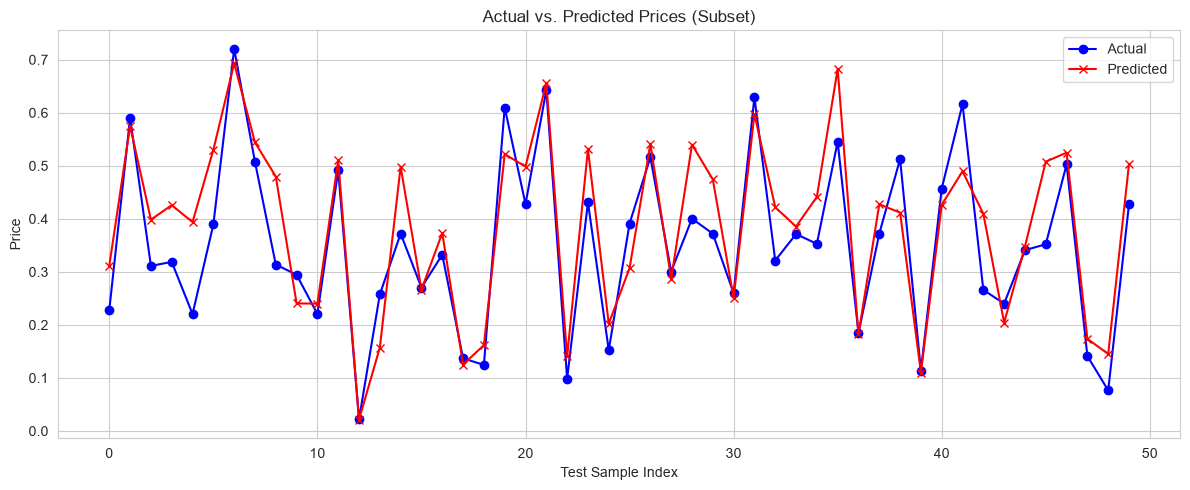

In [17]:
# Line plot for a subset of the test set
subset = 50
plt.figure(figsize=(12, 5))
plt.plot(range(subset), y_test.values[:subset], marker='o', label='Actual', color='blue')
plt.plot(range(subset), y_pred[:subset], marker='x', label='Predicted', color='red')
plt.title('Actual vs. Predicted Prices (Subset)')
plt.xlabel('Test Sample Index')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('../line_plot.png', dpi=150)
plt.show()

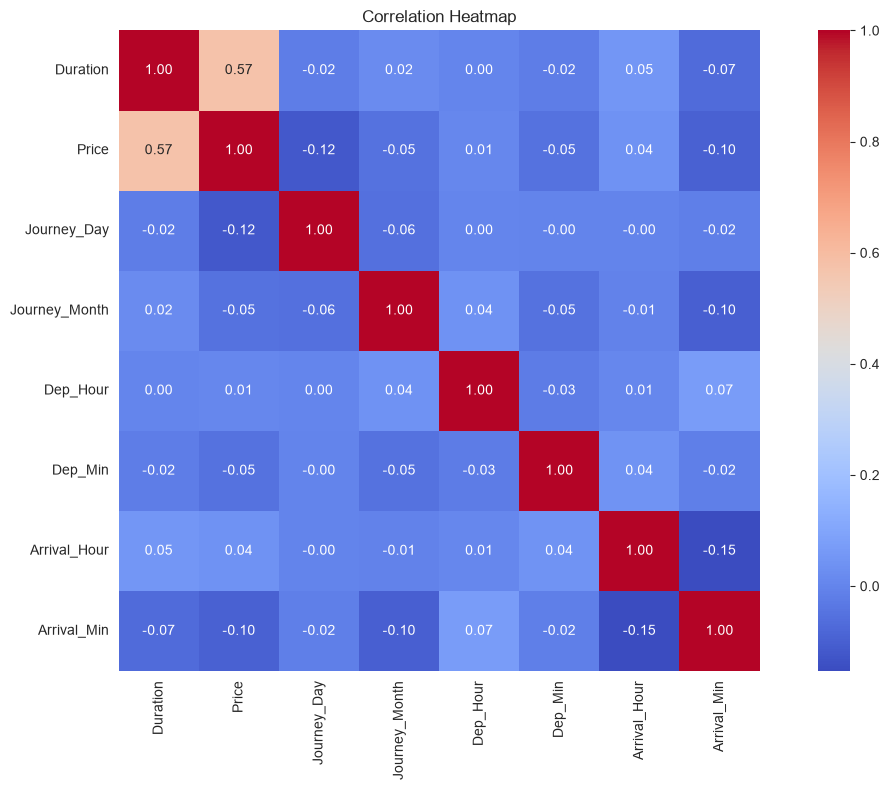

Duration vs Price correlation: 0.572


In [18]:
# Heatmap : Correlation of features
numeric_df = data.select_dtypes(include=['number'])
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm',
            fmt='.2f', cbar=True, square=True)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('../heatmap.png', dpi=150)
plt.show()

# Duration vs Price correlation (from the PDF)
if 'Duration' in data.columns and 'Price' in data.columns:
    print("Duration vs Price correlation:",
          data['Duration'].corr(data['Price']).round(3))

In [19]:
import joblib

joblib.dump(mlp, '../flight_price_mlp.pkl')
joblib.dump(scaler, '../flight_price_scaler.pkl')
print("Model and scaler saved.")

Model and scaler saved.


In [20]:
# Convert normalized predictions back to actual INR values
y_pred_actual = y_pred * (y_max - y_min) + y_min
y_test_actual = y_test * (y_max - y_min) + y_min

print("Sample actual vs predicted prices (INR):")
for a, p in list(zip(y_test_actual.values[:10], y_pred_actual[:10])):
    print(f"  Actual: {a:8.2f}   Predicted: {p:8.2f}")

Sample actual vs predicted prices (INR):
  Actual:  6610.00   Predicted:  8381.54
  Actual: 14300.00   Predicted: 13971.74
  Actual:  8372.00   Predicted: 10223.63
  Actual:  8529.00   Predicted: 10802.18
  Actual:  6442.00   Predicted: 10125.54
  Actual: 10031.00   Predicted: 13020.26
  Actual: 17057.00   Predicted: 16484.50
  Actual: 12537.00   Predicted: 13317.06
  Actual:  8425.00   Predicted: 11949.43
  Actual:  8016.00   Predicted:  6868.95


In [21]:
# Save feature column names so the web app can build inputs correctly
import joblib
feature_columns = X.columns.tolist()
joblib.dump(feature_columns, '../feature_columns.pkl')

# Also print y_min and y_max for the app
print("y_min:", y_min)
print("y_max:", y_max)
print("Total features:", len(feature_columns))
print("Features:", feature_columns)

y_min: 1759
y_max: 23001
Total features: 31
Features: ['Duration', 'Journey_Day', 'Journey_Month', 'Dep_Hour', 'Dep_Min', 'Arrival_Hour', 'Arrival_Min', 'Airline_Air India', 'Airline_GoAir', 'Airline_IndiGo', 'Airline_Jet Airways', 'Airline_Jet Airways Business', 'Airline_Multiple carriers', 'Airline_Multiple carriers Premium economy', 'Airline_SpiceJet', 'Airline_Trujet', 'Airline_Vistara', 'Airline_Vistara Premium economy', 'Source_Chennai', 'Source_Delhi', 'Source_Kolkata', 'Source_Mumbai', 'Destination_Cochin', 'Destination_Delhi', 'Destination_Hyderabad', 'Destination_Kolkata', 'Destination_New Delhi', 'Total_Stops_2 stops', 'Total_Stops_3 stops', 'Total_Stops_4 stops', 'Total_Stops_non-stop']
